#Bivariate Analysis
> Understand relationships between two variables

###Setup

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr
sns.set_style('whitegrid')
pd.set_option('display.max_columns', 50)

###Load Dataset

In [9]:
import kagglehub
path = kagglehub.dataset_download("yasserh/titanic-dataset")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'titanic-dataset' dataset.
Path to dataset files: /kaggle/input/titanic-dataset


In [10]:
import shutil as st
st.copytree(path,'/content/datasets',dirs_exist_ok=True)

'/content/datasets'

In [11]:
df = pd.read_csv('/content/datasets/titanic_dataset.csv')
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [12]:
df.dtypes

,0
survived,int64
pclass,int64
sex,object
age,float64
sibsp,int64
parch,int64
fare,float64
embarked,object
class,object
who,object


In [13]:
numCol = ['age','fare','sibsp','parch']
catCol = ['survived', 'pclass', 'sex', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alone']


In [14]:
dfNum = df[numCol].dropna()

In [15]:
dfNum.head()

,age,fare,sibsp,parch
0,22.0,7.2500,1,0
1,38.0,71.2833,1,0
2,26.0,7.9250,0,0
3,35.0,53.1000,1,0
4,35.0,8.0500,0,0


In [16]:
df['survivedLabel'] = df['survived'].map({0:'No',1:'Yes'})
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,survivedLabel
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False,No
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False,Yes
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True,Yes
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False,Yes
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True,No


###Numerical vs Numerical

In [17]:
dfNum.head()

,age,fare,sibsp,parch
0,22.0,7.2500,1,0
1,38.0,71.2833,1,0
2,26.0,7.9250,0,0
3,35.0,53.1000,1,0
4,35.0,8.0500,0,0


####Scatter Plot

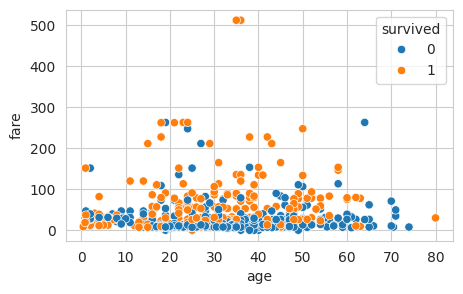

In [18]:
plt.figure(figsize=(5,3))
sns.scatterplot(x=df['age'],y=df['fare'],hue=df['survived'])
plt.show()

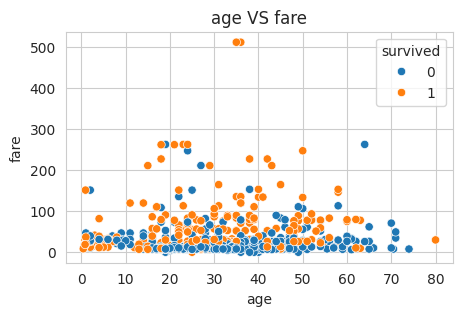

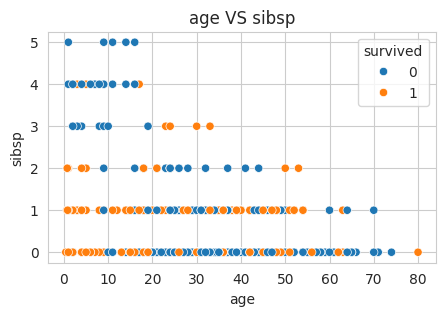

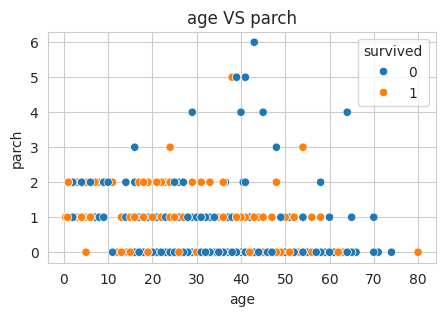

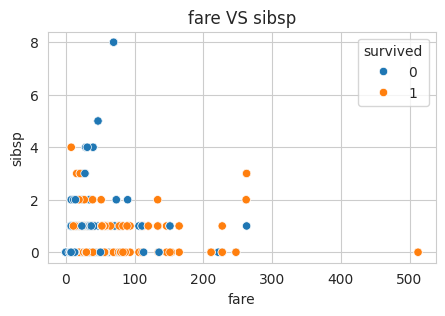

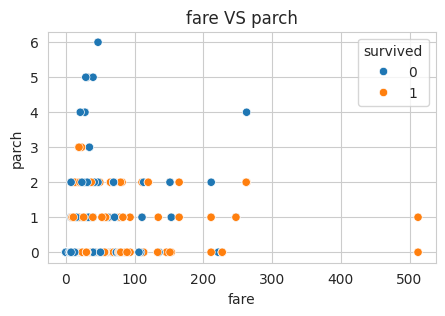

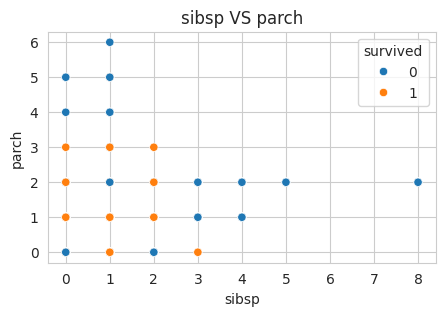

In [19]:
numPair = [
    ('age','fare'),
    ('age','sibsp'),
    ('age','parch'),
    ('fare','sibsp'),
    ('fare','parch'),
    ('sibsp','parch')
]
for x,y in numPair:
  plt.figure(figsize=(5,3))
  plt.title(f"{x} VS {y}")
  sns.scatterplot(x=df[x],y=df[y],hue=df['survived'])
  plt.show()

####correlation Matrix

In [20]:
dfNum.corr()

,age,fare,sibsp,parch
age,1.000000,0.096067,-0.308247,-0.189119
fare,0.096067,1.000000,0.138329,0.205119
sibsp,-0.308247,0.138329,1.000000,0.383820
parch,-0.189119,0.205119,0.383820,1.000000


####Pearson correlation
>Pearson correlation is a statistical method used to measure the strength and direction of the linear relationship between two numerical variables.
### Pearson Correlation (r) Interpretation

| Correlation (r) | Interpretation |
|:---:|:---|
| +1.0 | Perfect Positive Correlation |
| +0.8 | Strong Positive Correlation |
| +0.5 | Moderate Positive Correlation |
| 0.0 | No Linear Correlation |
| -0.5 | Moderate Negative Correlation |
| -0.8 | Strong Negative Correlation |
| -1.0 | Perfect Negative Correlation |
<br>
* r = How strong is the relationship?
* p = How strong is the statistical evidence that the population relationship is non-zero?
<br>

* Sample: The data you collected.
* Population: The entire group you want to understand.
* r: The correlation you calculated from your sample.
* ρ (rho): The actual correlation in the population.
* p: How surprising your sample result would be if the population correlation were zero.
> **The big idea:** We calculate correlation using our available data, but we use statistical significance to understand whether the observed relationship provides convincing evidence of a relationship in the larger population.
<br>
### P-value (p) Interpretation

| P-value Range | Interpretation |
|:---:|:---|
| 0.00 - 0.001 | Very strong evidence against H₀ |
| 0.001 - 0.01 | Strong evidence against H₀ |
| 0.01 - 0.05 | Statistically significant |
| 0.05 - 1.00 | Not statistically significant |

**Significance Level (α) = 0.05**

- If p < 0.05 → Reject the null hypothesis (H₀).
- If p >= 0.05 → Fail to reject the null hypothesis (H₀).

**Note:** A smaller p-value indicates stronger evidence against H₀. It does not measure correlation strength.

In [21]:
for col in numCol:
  r,p = pearsonr(df[col],df['fare'])
  print(f"{col} vs fare: r={r:.3f} p={p:.3f}")

age vs fare: r=nan p=nan
fare vs fare: r=1.000 p=0.000
sibsp vs fare: r=0.160 p=0.000
parch vs fare: r=0.216 p=0.000


###Numerical VS Categorical Features

####Boxplot

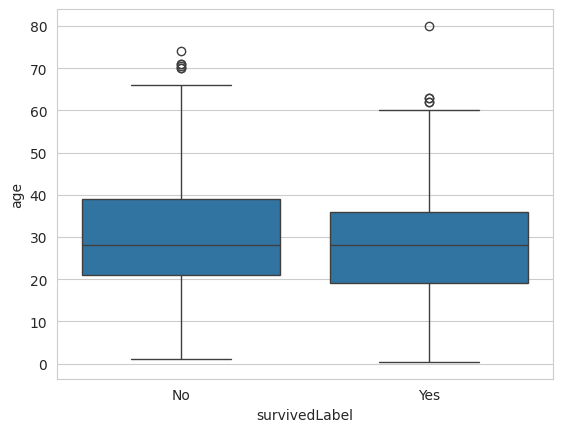

In [29]:
plt.Figure(figsize=(5,3))
sns.boxplot(x=df['survivedLabel'],y=df['age'])
plt.xlabel('survivedLabel')
plt.ylabel('age')
plt.show()

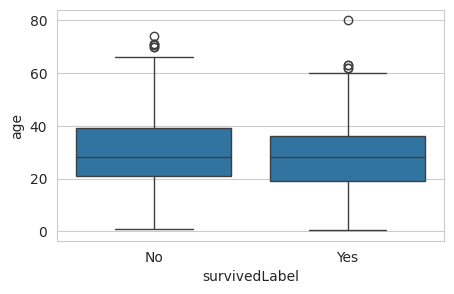

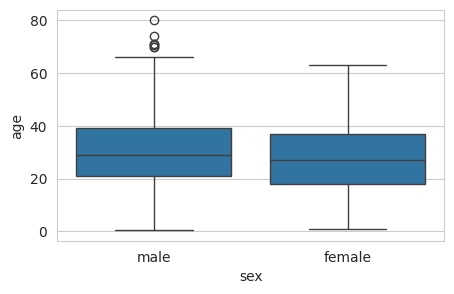

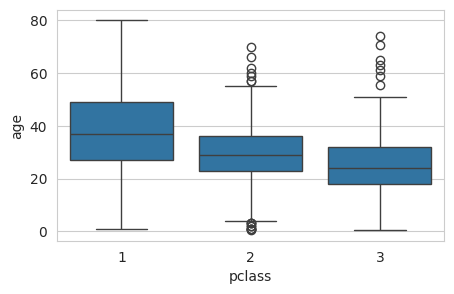

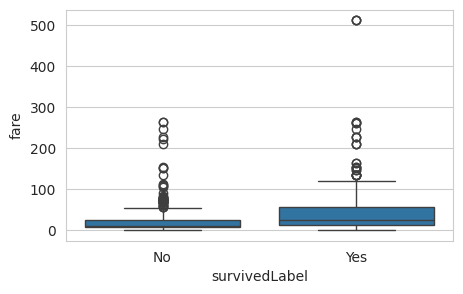

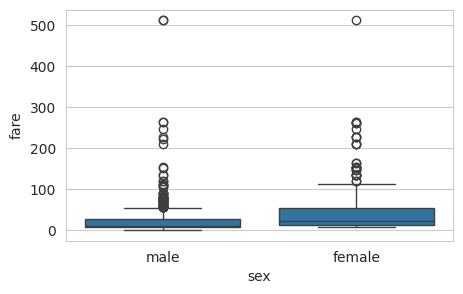

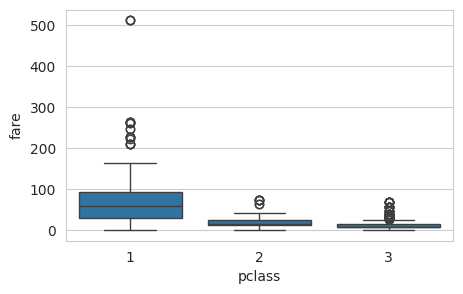

In [28]:
numColBox = ['age','fare']
catColBox = ['survivedLabel','sex','pclass']
for X in numColBox:
  for Y in catColBox:
    plt.figure(figsize=(5,3))
    sns.boxplot(x=df[Y],y=df[X])
    plt.xlabel(Y)
    plt.ylabel(X)
    plt.show()

####Grouped Statistics
> groupby() is used to divide data into groups based on one or more columns and then perform calculations on each group separately.

In [30]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,survivedLabel
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False,No
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False,Yes
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True,Yes
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False,Yes
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True,No


In [52]:
#df[numCol+['survivedLabel']].groupby('survivedLabel').mean()
df.groupby(['survivedLabel','sex'])[numCol].mean()

age       fare     sibsp     parch
survivedLabel sex                                             
No            female  25.046875  23.024385  1.209877  1.037037
              male    31.618056  21.960993  0.440171  0.207265
Yes           female  28.847716  51.938573  0.515021  0.515021
              male    27.276022  40.821484  0.385321  0.357798

In [51]:
for col in catCol:
  print(df.groupby(col)['fare'].describe())
  print('-'*50)

          count       mean        std  min      25%   50%   75%       max
survived                                                                 
0         549.0  22.117887  31.388207  0.0   7.8542  10.5  26.0  263.0000
1         342.0  48.395408  66.596998  0.0  12.4750  26.0  57.0  512.3292
--------------------------------------------------
        count       mean        std  min       25%      50%   75%       max
pclass                                                                     
1       216.0  84.154687  78.380373  0.0  30.92395  60.2875  93.5  512.3292
2       184.0  20.662183  13.417399  0.0  13.00000  14.2500  26.0   73.5000
3       491.0  13.675550  11.778142  0.0   7.75000   8.0500  15.5   69.5500
--------------------------------------------------
        count       mean        std   min        25%   50%    75%       max
sex                                                                        
female  314.0  44.479818  57.997698  6.75  12.071875  23.0  55.00  512

###Categorical VS Categorical   

####Crosstab Example
### Crosstab Normalization Summary

**1. `normalize='columns'`**
- Each column sums to 1 (100%).
- Shows the distribution of survival status within each gender.
- Example: 74.20% of females survived, while 18.89% of males survived.
- Answers: What happened within each gender?

**2. `normalize='index'`**
- Each row sums to 1 (100%).
- Shows the gender distribution within each survival group.
- Example: Among survivors, 68.13% were female and 31.87% were male.
- Answers: What genders make up each survival group?

**3. `normalize='all'`**
- The entire table sums to 1 (100%).
- Shows each category combination as a percentage of the entire dataset.
- Example: 52.53% of all passengers were males who did not survive.
- Answers: What percentage of the entire dataset belongs to each combination?

### Quick Comparison

| Normalization | What sums to 100%? |
|---|---|
| `columns` | Each column |
| `index` | Each row |
| `all` | Entire table |

**Remember:**
- `columns` = Distribution within columns.
- `index` = Distribution within rows.
- `all` = Distribution within the entire dataset.

**EDA Tip:** Use `normalize='columns'` when comparing survival rates across genders.

In [61]:
print(pd.crosstab(df['survivedLabel'],df['sex'],normalize='columns'))
print('-'*50)
print(pd.crosstab(df['survivedLabel'],df['sex'],normalize='index'))
print('-'*50)
print(pd.crosstab(df['survivedLabel'],df['sex'],normalize='all'))

sex              female      male
survivedLabel                    
No             0.257962  0.811092
Yes            0.742038  0.188908
--------------------------------------------------
sex              female      male
survivedLabel                    
No             0.147541  0.852459
Yes            0.681287  0.318713
--------------------------------------------------
sex              female      male
survivedLabel                    
No             0.090909  0.525253
Yes            0.261504  0.122334


####Countplot

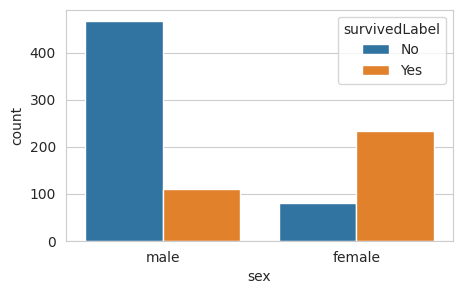

In [64]:
plt.figure(figsize=(5,3))
sns.countplot(data=df,x='sex',hue='survivedLabel')
plt.show()